# Regression on house prices - advanced

I will predict the impact probability based of an asteroid based on its characteristics.
TODO: explain the advanced methods used

In [269]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from pandas.plotting import scatter_matrix
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

### 1. Data preparation
I will reuse some of the findings from my Data Exploration Advanced notebook, where I used the exact same dataset as in this one.

In [270]:
impacts = pd.read_csv("impacts.csv")
impacts["Period Length"] = impacts["Period End"] - impacts["Period Start"]

I added a new column to the dataset, which measures how long the period lasts for each asteroid. This might correlate with impact probability or number of impacts, because it has a longer time window where it can hit.

In [271]:
impacts.info()
impacts.describe()

<class 'pandas.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Object Name                    683 non-null    str    
 1   Period Start                   683 non-null    int64  
 2   Period End                     683 non-null    int64  
 3   Possible Impacts               683 non-null    int64  
 4   Cumulative Impact Probability  683 non-null    float64
 5   Asteroid Velocity              683 non-null    float64
 6   Asteroid Magnitude             683 non-null    float64
 7   Asteroid Diameter (km)         683 non-null    float64
 8   Cumulative Palermo Scale       683 non-null    float64
 9   Maximum Palermo Scale          683 non-null    float64
 10  Maximum Torino Scale           683 non-null    str    
 11  Period Length                  683 non-null    int64  
dtypes: float64(6), int64(4), str(2)
memory usage: 64.2 KB


,Period Start,Period End,Possible Impacts,Cumulative Impact Probability,Asteroid Velocity,Asteroid Magnitude,Asteroid Diameter (km),Cumulative Palermo Scale,Maximum Palermo Scale,Period Length
count,683.000000,683.000000,683.000000,6.830000e+02,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000
mean,2062.573939,2099.680820,43.348463,1.539476e-04,11.462577,26.158272,0.049378,-6.511552,-6.804012,37.106881
std,43.501694,37.594698,113.773280,2.519607e-03,6.067772,2.388296,0.156403,1.509189,1.476135,32.930861
min,2017.000000,2017.000000,1.000000,1.100000e-10,0.340000,15.600000,0.002000,-10.980000,-11.000000,0.000000
25%,2034.000000,2090.000000,2.000000,1.100000e-07,7.240000,25.000000,0.010000,-7.490000,-7.790000,5.000000
50%,2061.000000,2109.000000,6.000000,1.700000e-06,10.500000,26.400000,0.017000,-6.460000,-6.790000,31.000000
75%,2085.000000,2114.000000,29.000000,1.550000e-05,14.810000,27.800000,0.033000,-5.490000,-5.865000,64.000000
max,2880.000000,2880.000000,1144.000000,6.500000e-02,39.470000,31.600000,2.579000,-1.420000,-1.420000,98.000000


In [272]:
impacts["Maximum Torino Scale"].value_counts()

Maximum Torino Scale
0      680
(*)      3
Name: count, dtype: int64

Since `Maximum Torino Scale` is all zeros except 3 invalid `(*)` values, we will drop the columns in the Pipeline. It's not useful for linear regression. As seen in my advanced data exploration notebook, all other columns are clean, they don't have any invalid/null values.

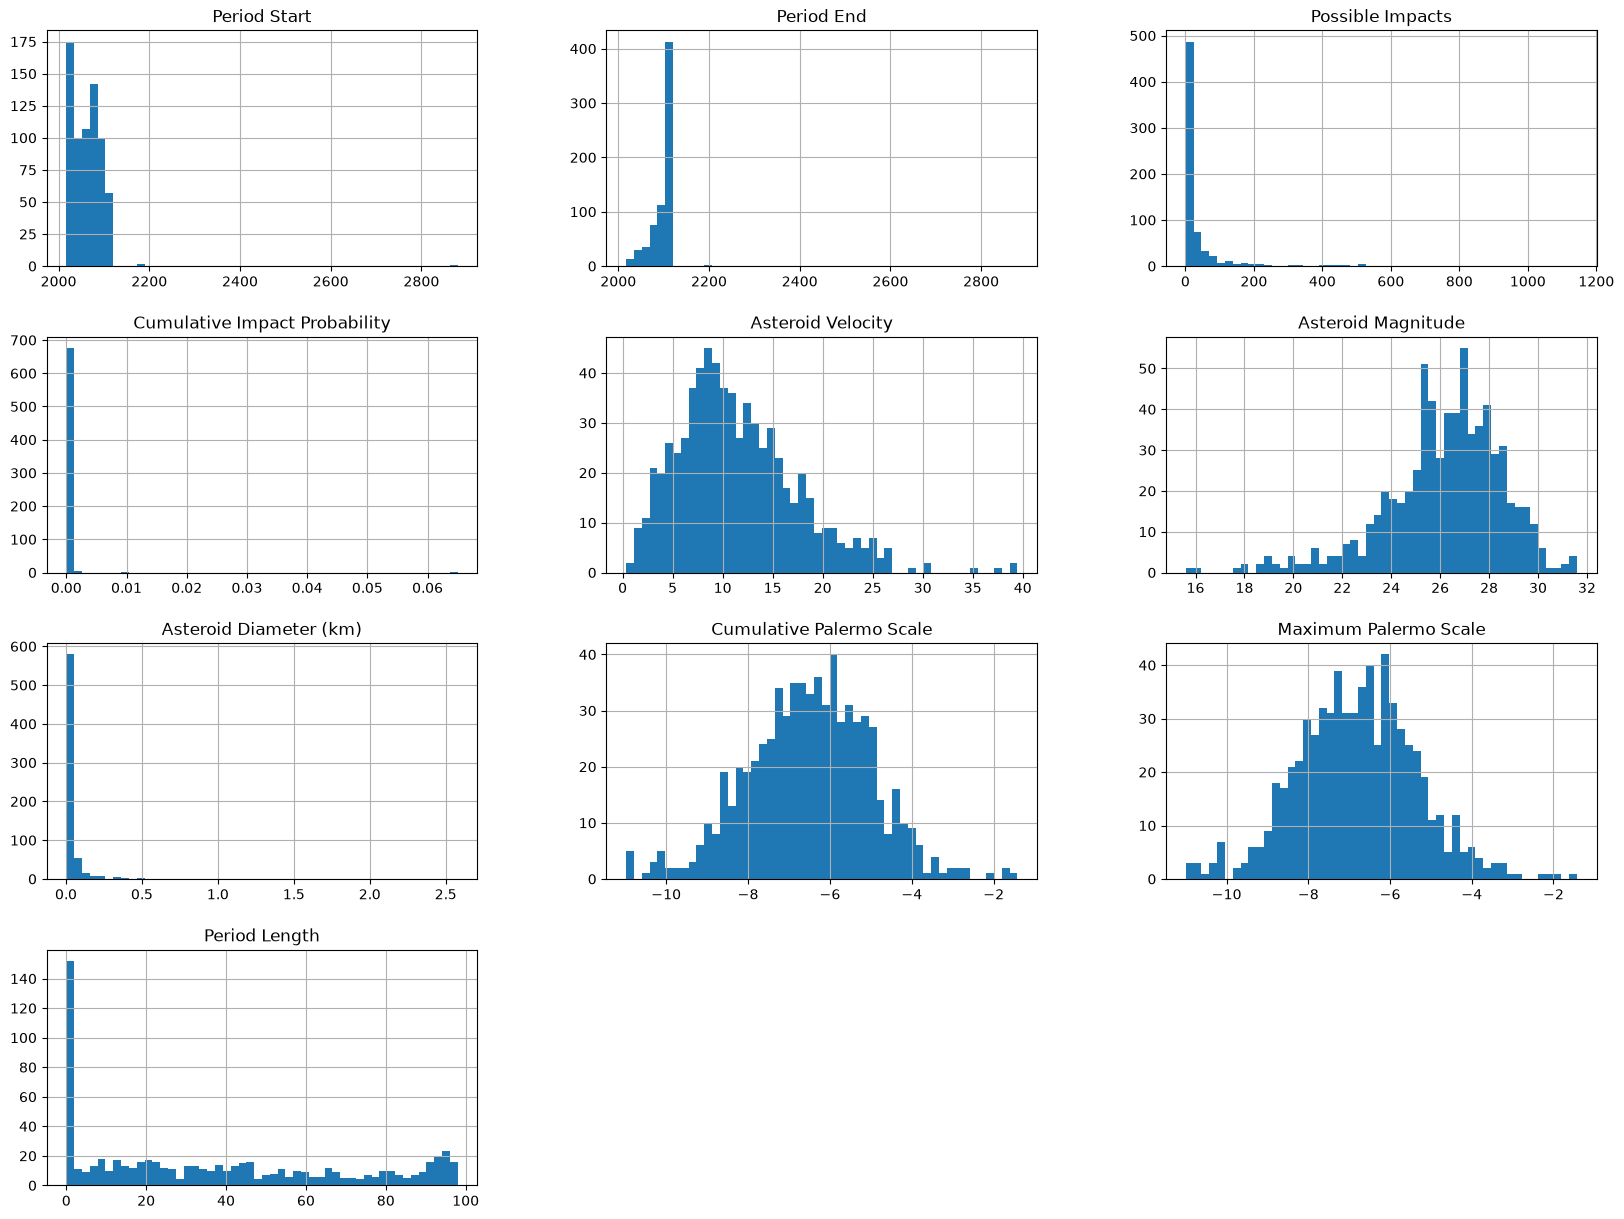

In [273]:
impacts.hist(bins=50, figsize=(20, 15))
plt.show()

Drawing histograms of all features to get a general understanding of how the data is distributed. We can see that some of them are very heavily skewed right.

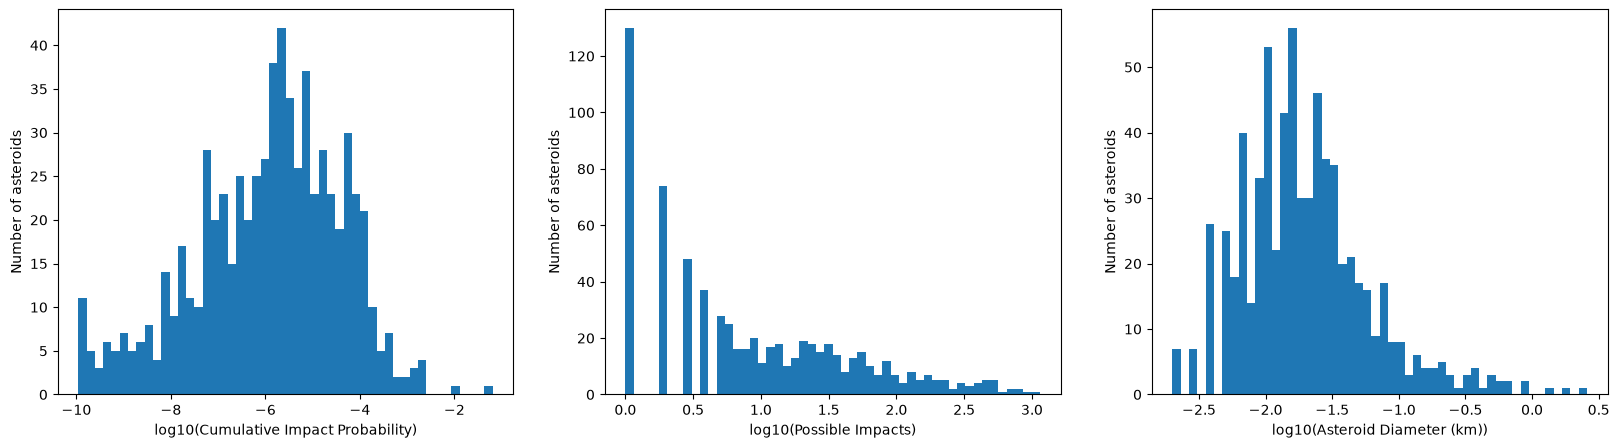

In [274]:
columns = ["Cumulative Impact Probability", "Possible Impacts", "Asteroid Diameter (km)"]
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, column in zip(axes, columns):
    ax.hist(np.log10(impacts[column]), bins=50)
    ax.set(xlabel=f"log10({column})", ylabel="Number of asteroids")

plt.show()

Log-plots of some heavily right skewed distributions.

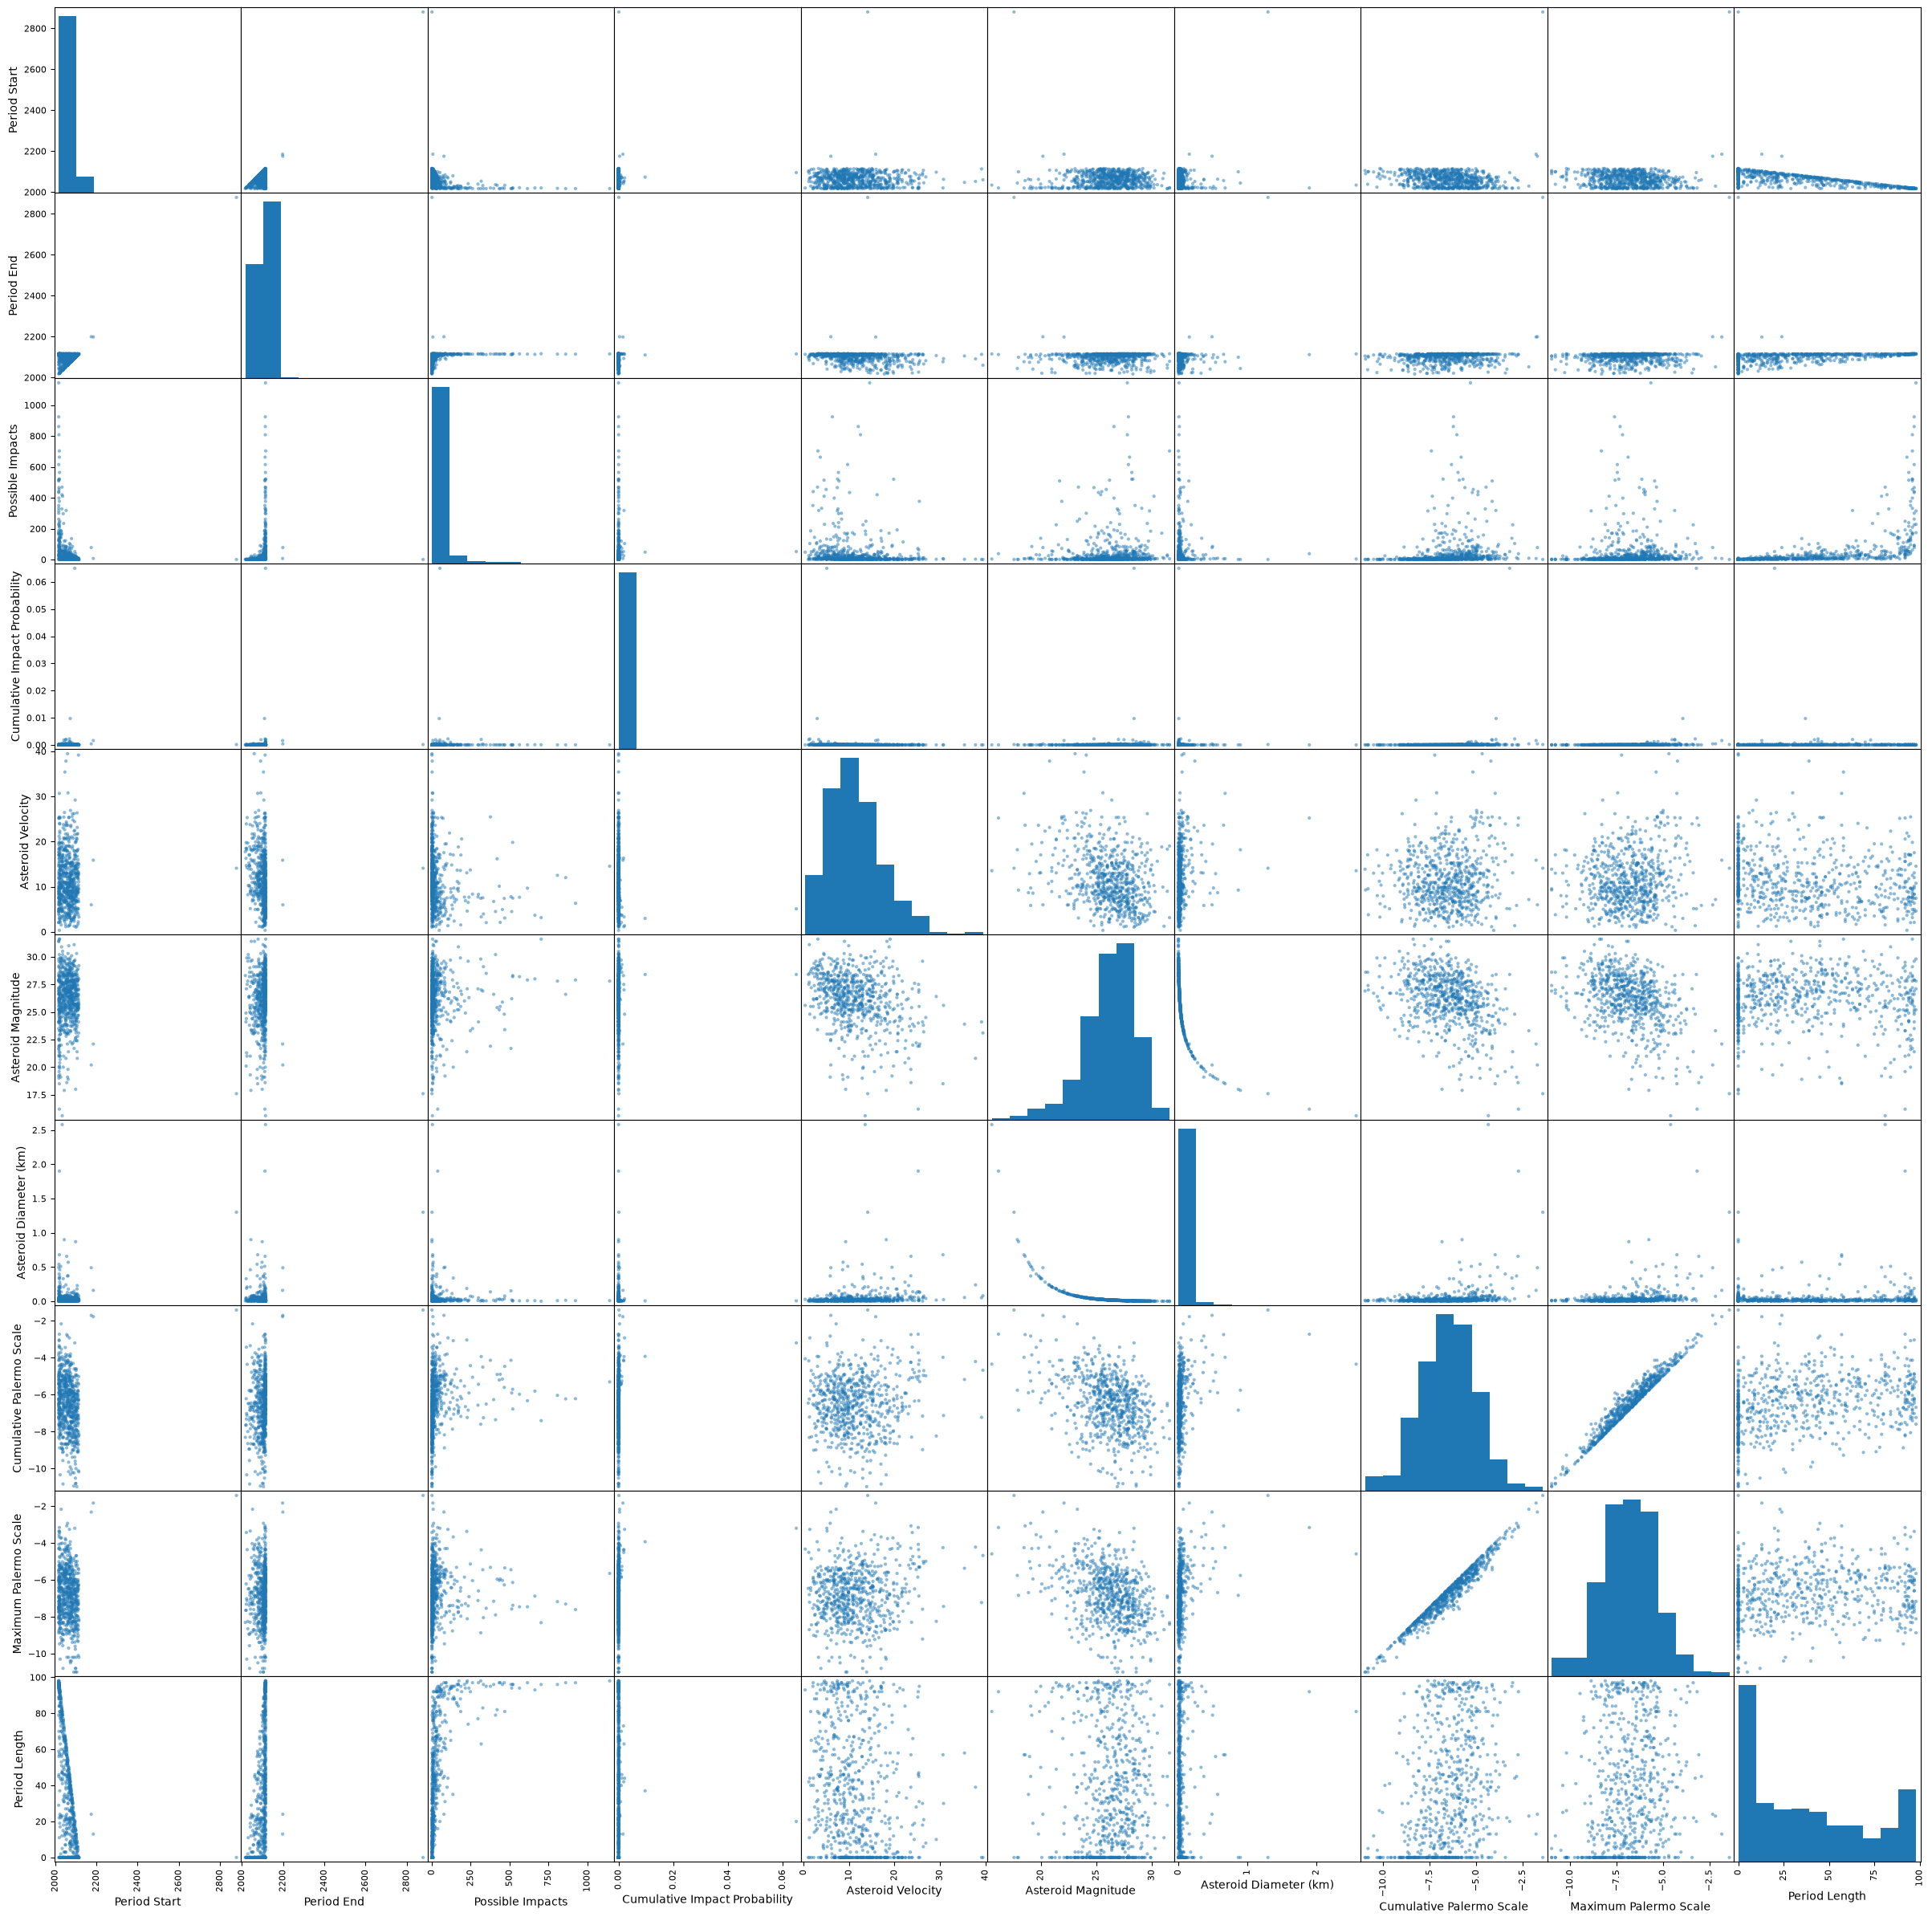

In [275]:
scatter_matrix(impacts, figsize=(30, 30))
plt.show()

Scatter plot of each feature against each feature. On the diagonal, there is a histogram for every feature. A correlation matrix is displayed below.





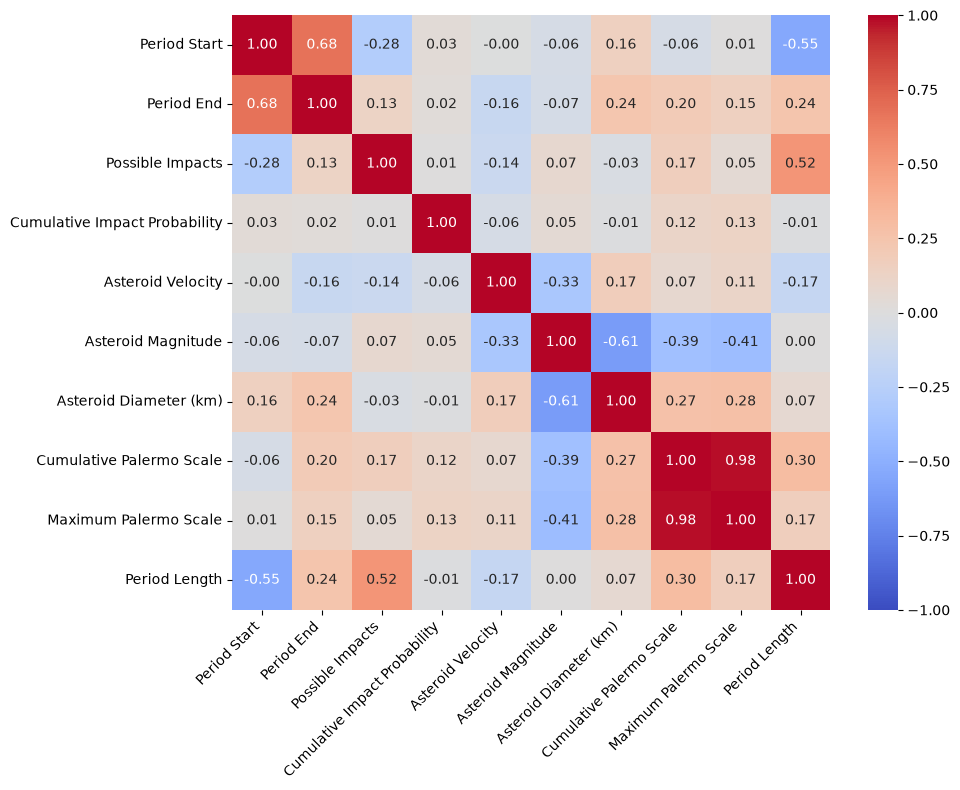

In [278]:
corr = impacts.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,       # print numbers inside cells
    fmt=".2f",        # two decimal places
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


The correlation matrix shows weak positive linear associations between raw impact probability and the Palermo scales. Period Length is moderately correlated with Possible Impacts, but has almost no linear association with raw impact probability. Since several variables are highly skewed, we will also examine correlations after log transformations. We will then use cross-validation to assess whether multiple predictors or interaction terms improve prediction.